# **A behavioural portfolio dashboard for an individual investor**
## **Integrative Project — Behavioural Finance**

---

**Authors:** Alan Jesús Hernández Soto · Francisco Uriel Ledezma Chávez · Esteban Vega Campos · Santiago Villegas Baltazar
**Programme:** Ingeniería Financiera
**Institution:** ITESO — Universidad Jesuita de Guadalajara
**Course:** Comportamiento en las Finanzas y Toma de Decisiones
**Professor:** Luis Felipe Gómez Estrada
**Date:** 24 November 2026

---

## Contents

0. [The project in plain terms](#s0)
1. [Part 1: the client profile](#s1)
   - [1.1 The instrument](#s11)
   - [1.2 What the estimators are, and why in that order](#s12)
   - [1.3 Checking the implementation against the course's own numbers](#s13)
2. [Part 2: portfolio construction](#s2)
   - [2.1 The model](#s21)
   - [2.2 What the optimiser does to an estimated mean](#s22)
   - [2.3 The portfolio this client is given](#s23)
3. [Part 3: the sequential decision problem](#s3)
   - [3.1 Step 1: the narrative](#s31)
   - [3.2 Step 2: core elements](#s32)
   - [3.3 Step 3: the mathematical model](#s33)
   - [3.4 Step 4: the uncertainty model](#s34)
   - [3.5 Step 5: designing policies](#s35)
   - [3.6 Step 6: evaluating policies](#s36)
4. [Results](#s4)
5. [Robustness, and what would change the recommendation](#s5)
6. [Recommendation to the client](#s6)
7. [Limitations](#s7)
8. [References](#s8)

<a id="s0"></a>

## 0. The project in plain terms

An advisory firm wants to tell a client three things at once: what kind of risk taker they are, what portfolio that implies, and what their own habits will cost them if they keep them. The first is a measurement problem, the second an optimisation problem, and the third a sequential decision problem, and this report does them in that order because each one feeds the next.

The measurement is ten questions whose answers identify the three parameters of a prospect-theory value function. The optimisation is a mixed-integer programme that picks at most ten funds out of twenty five subject to minimum lots and a cap on each asset class, and whose risk aversion is set by the client's own loss aversion. The decision problem is ten years of months in which six policies, two of them written to imitate the client rather than to help them, are run over the same simulated scenarios so that any difference between them is the policy and not the draw.

In [1]:
# A kernel left running keeps the version of the package it first imported, and
# "Run All" does not restart it, so an edit to src/ would otherwise go unseen.
%load_ext autoreload
%autoreload 2

import os, sys, pathlib, warnings

HERE = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / "src" / "bpd").is_dir())
os.chdir(HERE)
sys.path.insert(0, str(HERE / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bpd import config, data, evaluate, policies, portfolio, profile, questionnaire, simulator

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

<a id="s1"></a>

## 1. Part 1: the client profile

<a id="s11"></a>

### 1.1 The instrument

Ten questions. The first four are lotteries whose answers identify the value function, the fifth fixes the reference point, and the last five are scenarios that set the behavioural flags, each of which names the policy it switches on in Part 3.

The lottery used for loss aversion is the opening exercise of the course's prospect-theory lecture, a fair coin that loses a thousand pesos on heads and pays an unknown gain on tails, and the client is asked for the smallest gain at which they would take it. The question is put as a ladder rather than as an open number, because a client asked to name a price invents one while a client asked to accept or refuse a sequence of concrete bets is doing something they recognise, which means the answer brackets the switch point instead of locating it and the midpoint of the bracket is used.

In [2]:
for item in questionnaire.QUESTIONS:
    print(f"{item['id']:<18}{item['measures']}")
    print(f"{'':18}{item['text']}")

q1_ladder         loss aversion
                  A fair coin is flipped. Heads you lose $1,000. Tails you win G. What is the smallest G at which you would take the bet?
q2_gain_ce        curvature over gains
                  A fair coin is flipped. Heads you win $10,000, tails you win nothing. What certain amount would you accept instead of the bet?
q3_loss_ce        curvature over losses
                  A fair coin is flipped. Heads you lose $10,000, tails you lose nothing. What certain loss would you accept instead of the bet?
q4_gain_ce_small  curvature, consistency check
                  The same bet at a smaller stake. Heads you win $2,000, tails nothing. What certain amount would you accept instead?
q5_reference      reference point
                  Ten years from now, which number will you compare your portfolio against?
q6_drawdown       panic selling
                  Your portfolio has fallen 20% in three months. What do you do?
q7_chasing        performance chasing
   

<a id="s12"></a>

### 1.2 What the estimators are, and why in that order

The three parameters are identified in the order $\beta$, $\alpha$, $\lambda$, and the order is forced by the algebra rather than chosen for convenience.

A loss-only lottery paying nothing or $-X$ with equal probability has prospect-theory value $-\tfrac{1}{2}\lambda X^{\beta}$, and the certain loss $c$ the client would accept instead satisfies $-\lambda c^{\beta} = -\tfrac{1}{2}\lambda X^{\beta}$. Loss aversion appears on both sides and cancels, which leaves $\beta = \ln(0.5) / \ln(c/X)$ and identifies curvature over losses without knowing $\lambda$ at all. The gain-only lottery gives $\alpha$ the same way. Only then does the mixed lottery identify loss aversion, through $\tfrac{1}{2} G^{\alpha} = \tfrac{1}{2}\lambda L^{\beta}$, so that $\lambda = G^{\alpha} / L^{\beta}$, which at $\alpha = \beta = 0.88$ and $L = 1000$ is the course's own $\hat\lambda = (G/1000)^{0.88}$.

Probabilities enter raw rather than weighted, which is what the lecture does when it writes that indifference condition with one half on both sides. The weighting function is still reported, as a diagnostic that tells the client how far their treatment of a stated probability departs from the probability itself, but it is kept out of the estimator so that the estimator remains the one the course derived.

In [3]:
answers = questionnaire.default_answers()
client = questionnaire.score(answers)

print(f"alpha  {client.alpha:.3f}   curvature over gains")
print(f"beta   {client.beta:.3f}   curvature over losses")
print(f"lambda {client.lam:.3f}   loss aversion")
print(f"gamma  {client.gamma:.2f}    risk aversion handed to Part 2")
print(f"reference point: {client.reference}")
print()
for name, on in client.flags.items():
    print(f"{name:<22}{'yes' if on else 'no'}")

alpha  0.880   curvature over gains
beta   0.880   curvature over losses
lambda 2.161   loss aversion
gamma  6.75    risk aversion handed to Part 2
reference point: A target I have in mind

panic_selling         yes
performance_chasing   yes
disposition           yes
narrow_framing        yes
anchoring             yes


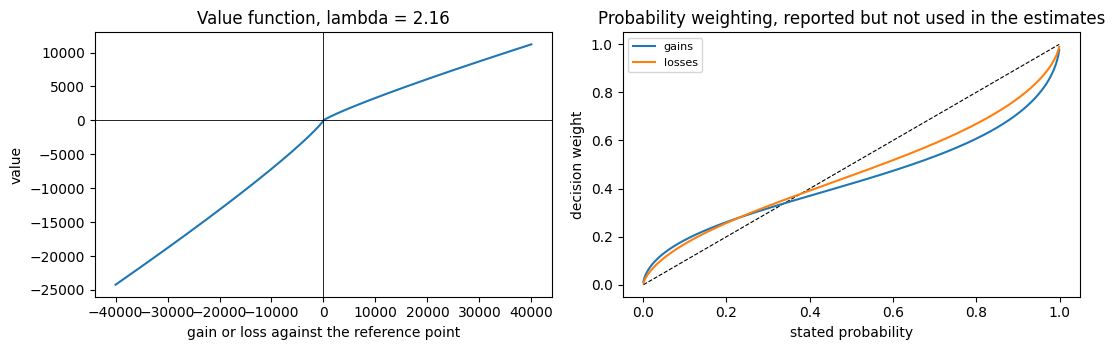

In [4]:
grid = np.linspace(-40_000, 40_000, 400)
probabilities = np.linspace(0.001, 0.999, 400)

figure, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
left.plot(grid, profile.value(grid, client.alpha, client.beta, client.lam))
left.axhline(0, linewidth=0.6, color="black")
left.axvline(0, linewidth=0.6, color="black")
left.set_xlabel("gain or loss against the reference point")
left.set_ylabel("value")
left.set_title(f"Value function, lambda = {client.lam:.2f}")

right.plot(probabilities, probabilities, linewidth=0.8, linestyle="--", color="black")
right.plot(probabilities, profile.weight(probabilities, config.GAMMA_PLUS), label="gains")
right.plot(probabilities, profile.weight(probabilities, config.GAMMA_MINUS), label="losses")
right.set_xlabel("stated probability")
right.set_ylabel("decision weight")
right.set_title("Probability weighting, reported but not used in the estimates")
right.legend(fontsize=8)
plt.tight_layout()
plt.savefig("results/figures/profile.png", dpi=120)
plt.show()

<a id="s13"></a>

### 1.3 Checking the implementation against the course's own numbers

An estimator that is wrong in the third decimal still produces a confident profile, so the implementation is checked against values that were published before we wrote it. The table below reproduces the loss-aversion ladder, the decision weights and the worked examples from the course's prospect-theory lecture, and the test suite asserts every one of them.

In [5]:
A = B = config.ALPHA_TK
checks = [
    ("lambda at G = 1500", profile.loss_aversion_from_g(1500, A, B), 1.43),
    ("lambda at G = 2000", profile.loss_aversion_from_g(2000, A, B), 1.84),
    ("lambda at G = 2500", profile.loss_aversion_from_g(2500, A, B), 2.24),
    ("lambda at G = 3000", profile.loss_aversion_from_g(3000, A, B), 2.63),
    ("lambda at G = 2513", profile.loss_aversion_from_g(2513, A, B), 2.25),
    ("w+(0.50)", profile.weight(0.50, config.GAMMA_PLUS), 0.421),
    ("w-(0.50)", profile.weight(0.50, config.GAMMA_MINUS), 0.454),
    ("w+(0.10)", profile.weight(0.10, config.GAMMA_PLUS), 0.186),
    ("w+(0.90)", profile.weight(0.90, config.GAMMA_PLUS), 0.712),
    ("v(-400)", profile.value(-400, A, B, 2.25), -438.5),
    ("half of v(-800)", 0.5 * profile.value(-800, A, B, 2.25), -403.5),
    ("note: v(-20,000)", profile.value(-20_000, A, B, 2.25), -13_712),
    ("note: v(+25,000)", profile.value(25_000, A, B, 2.25), 7_416),
]
rows = [{"quantity": name, "ours": value, "course": published,
         "agrees": abs(value - published) <= max(0.005, abs(published) * 0.0005)}
        for name, value, published in checks]
print(pd.DataFrame(rows).to_string(index=False))
print()
print(f"all {len(rows)} agree: {all(r['agrees'] for r in rows)}")

          quantity                ours     course  agrees
lambda at G = 1500            1.428763      1.430    True
lambda at G = 2000            1.840375      1.840    True
lambda at G = 2500            2.239686      2.240    True
lambda at G = 3000            2.629461      2.630    True
lambda at G = 2513            2.249932      2.250    True
          w+(0.50)            0.420639      0.421    True
          w-(0.50)            0.453988      0.454    True
          w+(0.10)            0.186303      0.186    True
          w+(0.90)            0.711716      0.712    True
           v(-400)  -438.5259625377816   -438.500    True
   half of v(-800)         -403.526175   -403.500    True
  note: v(-20,000) -13711.624592663055 -13712.000    True
  note: v(+25,000)  7416.2986048930625   7416.000    True

all 13 agree: True


<a id="s2"></a>

## 2. Part 2: portfolio construction

<a id="s21"></a>

### 2.1 The model

The objective is mean-variance in the utility form the course uses, maximising $w^{\top}\mu - \tfrac{\gamma}{2} w^{\top}\Sigma w$ subject to the weights summing to one. The brief offers mean-CVaR as an alternative and we did not take it, because mean-variance is the objective the course develops, audits and criticises at length while conditional value at risk appears nowhere in its material, and an objective we could not defend from the course would be the weakest part of the report.

Four constraints turn it into a mixed-integer programme. A binary $z_i$ marks whether fund $i$ is held at all; at most $K$ of them may be one; a held position is at least $l$ and at most $u$ of the portfolio, written $l z_i \le w_i \le u z_i$ so that one pair of inequalities enforces the lot size and the link to the binary at the same time; and the weight of each asset class is capped.

Risk aversion is not asked for. It is set from the client's loss aversion, linearly between two anchors as $\lambda$ runs across the range the course reports for published estimates. That map is ours rather than the course's, and it is the first of the three choices this report flags as its own.

In [6]:
prices = data.load_prices()
rets = data.monthly_returns(prices)
mu, sigma = data.moments(rets)
classes = [config.ASSET_CLASS[t] for t in config.TICKERS]

print(f"{len(rets)} monthly returns, {rets.index[0].date()} to {rets.index[-1].date()}, "
      f"{rets.shape[1]} funds, no missing values: {not rets.isna().any().any()}")
print(f"asset classes: {', '.join(config.CLASSES)}")

129 monthly returns, 2016-02-29 to 2026-10-31, 25 funds, no missing values: True
asset classes: Cash, Fixed income, Non-US equity, Real assets, US equity


<a id="s22"></a>

### 2.2 What the optimiser does to an estimated mean

The course spends a lecture on why this model misbehaves, and the misbehaviour is not a bug to be fixed but a property to be managed, so it is worth stating before the portfolio is shown rather than after.

Three results from that lecture apply directly. Merton's shows that the standard error of an estimated mean is $\sigma/\sqrt{T}$ and depends only on the calendar span of the sample, so no amount of higher-frequency data improves it, and the lecture tabulates over a thousand years of US large-cap history as the span needed to pin a mean to fifty basis points. Chopra and Ziemba's shows that errors in means cost about ten times what errors in covariances cost, so effort spent cleaning $\Sigma$ is effort spent on the input that matters least. Michaud's names what follows: the optimiser prefers assets with a high estimated mean, a low estimated variance and a low estimated correlation, which are exactly the assets most likely to be carrying a positive estimation error, so the objective and the error point the same way.

Our response is the one the course prescribes. Jagannathan and Ma show that a binding long-only constraint is algebraically identical to shrinking the covariance matrix, which means a long-only optimiser that behaves well is running an undocumented shrinkage estimator, and the lecture's advice is to shrink on purpose instead. So the sample mean is pulled toward its cross-sectional average by a stated intensity before it reaches the optimiser, the covariance is left as the sample covariance because it is the least damaging input, and the report shows what the whole range of that intensity does. At an intensity of one every fund has the same expected mean and the programme returns the minimum-variance portfolio, which is the frontier portfolio that refuses to use the input it cannot estimate.

In [7]:
rows = []
for shrink in (0.0, 0.25, 0.50, 0.75, 1.0):
    mu_s, sigma_s = data.moments(rets, shrink=shrink)
    w_s, report_s = portfolio.solve(mu_s, sigma_s, classes, client.gamma / 2.0)
    held = [(config.TICKERS[i], w_s[i]) for i in np.argsort(-w_s) if w_s[i] > 1e-9]
    rows.append({"shrink": shrink, "holdings": report_s["held"],
                 "largest": w_s.max(),
                 "expected a year": report_s["expected_monthly"] * 12,
                 "volatility a year": report_s["monthly_vol"] * np.sqrt(12),
                 "portfolio": ", ".join(f"{t} {100 * v:.0f}" for t, v in held)})
shrink_table = pd.DataFrame(rows)
print(shrink_table.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

Restricted license - for non-production use only - expires 2028-11-29


 shrink  holdings  largest  expected a year  volatility a year                                                       portfolio
  0.000         6    0.350            0.148              0.104                    XLK 35, GLD 25, BIL 17, DBC 15, QQQ 5, EFA 3
  0.250         6    0.350            0.132              0.097                    XLK 35, GLD 26, BIL 20, DBC 14, XLV 3, XLE 2
  0.500         5    0.304            0.119              0.091                          XLK 30, GLD 24, BIL 20, DBC 16, XLV 10
  0.750         6    0.350            0.096              0.050                   BIL 35, SHY 20, XLK 15, GLD 13, DBC 10, XLV 6
  1.000         9    0.350            0.101              0.027 BIL 35, SHY 35, DBC 8, GLD 5, IEF 5, XLV 5, XLP 3, XLK 2, XLU 2


<a id="s23"></a>

### 2.3 The portfolio this client is given

In [8]:
target, build_report = portfolio.solve(mu, sigma, classes, client.gamma / 2.0)
held = pd.DataFrame({"fund": config.TICKERS, "asset class": classes, "weight": target})
held = held[held.weight > 1e-9].sort_values("weight", ascending=False)
print(held.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print()
print(f"holdings {build_report['held']} of at most {config.K_MAX}, "
      f"weights sum to {target.sum():.6f}, smallest held position {held.weight.min():.3f} "
      f"against a minimum lot of {config.MIN_POSITION}")
print(f"expected {build_report['expected_monthly'] * 12:.2%} a year, "
      f"volatility {build_report['monthly_vol'] * np.sqrt(12):.2%} a year, "
      f"optimality gap {build_report['gap']:.4f}")
print()
by_class = held.groupby("asset class").weight.sum().sort_values(ascending=False)
print(by_class.to_string(float_format=lambda v: f"{v:.3f}"))
print(f"class cap {config.CLASS_CAP}")

fund asset class  weight
 XLK   US equity  0.3038
 GLD Real assets  0.2401
 BIL        Cash  0.2000
 DBC Real assets  0.1599
 XLV   US equity  0.0962

holdings 5 of at most 10, weights sum to 1.000000, smallest held position 0.096 against a minimum lot of 0.02
expected 11.87% a year, volatility 9.11% a year, optimality gap 0.0000

asset class
Real assets   0.400
US equity     0.400
Cash          0.200
class cap 0.4


<a id="s3"></a>

## 3. Part 3: the sequential decision problem

<a id="s31"></a>

### 3.1 Step 1: the narrative

A client puts a sum into the portfolio of Part 2 and leaves it for ten years, and once a month they may trade. Prices move in between, so the weights they wake up to are never quite the weights they chose, and every trade that restores them is paid for in commission. The client also watches, and what they do when they watch is the point of the exercise, because the two things their questionnaire says about them are that a large fall would move them to cash and that a year of one fund beating another would move money toward the winner.

Nothing forces the client to act in any month, and the cost of acting is certain while the cost of not acting is a portfolio that slowly stops being the one they were sold. That is the trade the whole problem turns on.

<a id="s32"></a>

### 3.2 Step 2: core elements

**Metrics.** Terminal wealth after ten years, the value the client places on it relative to their target, the worst fall along the way, and what the trading cost.

**Decisions.** The trade made at the start of each month, expressed as a change in weights.

**Sources of uncertainty.** The returns of twenty five funds in each of a hundred and twenty months.

**Known at the outset.** The portfolio from Part 2, the client's three parameters and their target, the commission of ten basis points, and the historical sample the scenarios are drawn from.

**Arrives over time.** The realised returns, one month at a time.

**What carries over.** Wealth, the weights the returns leave behind, and the highest wealth reached so far, which is what any statement about a drawdown is measured against. These are what make the problem sequential rather than a hundred and twenty unrelated choices.

<a id="s33"></a>

### 3.3 Step 3: the mathematical model

**State.** $S_t = (W_t, w_t, M_t, I_t, H_t)$, where $W_t$ is wealth in pesos at the start of month $t$, $w_t$ the vector of portfolio weights, which is dimensionless and sums to one, $M_t = \max_{s \le t} W_s$ the peak wealth in pesos, $I_t$ the value in pesos that the target portfolio would have reached had it never been touched, and $H_t$ the last twelve months of returns. The first two are physical states, the last three informational.

$I_t$ earns its place in the state. A client who has moved to cash has no drawdown of their own left to recover from, because cash does not fall, so a rule that returns them to the market after a recovery has to read the recovery off the market, and $I_t$ is the cheapest thing that carries it.

**Decision.** $x_t = w_t^{+} - w_t$, the change in weights executed at the start of month $t$, giving post-trade weights $w_t^{+}$ that are non-negative and sum to one. Everything in $S_t$ is known when $x_t$ is chosen, and the return of month $t+1$ is not.

**Exogenous information.** $W_{t+1} = r_{t+1} \in \mathbb{R}^{25}$, the returns realised during month $t+1$.

**Transition function.**

$$
\begin{aligned}
\text{cost}_t &= c \, \textstyle\sum_i |x_{t,i}| \, W_t, \qquad c = 0.0010\\
W_{t+1} &= (W_t - \text{cost}_t)\,\bigl(1 + w_t^{+\top} r_{t+1}\bigr)\\
w_{t+1} &= w_t^{+} \odot (1 + r_{t+1}) \,/\, \bigl(1 + w_t^{+\top} r_{t+1}\bigr)\\
M_{t+1} &= \max\{M_t,\, W_{t+1}\}\\
I_{t+1} &= I_t \,\bigl(1 + w_{\text{target}}^{\top} r_{t+1}\bigr)
\end{aligned}
$$

The commission is charged on every peso that changes hands, which is $\sum_i |x_i|$, and not on the half of that sum the course calls turnover. The two differ by a factor of two and confusing them would halve or double every cost in the report, so turnover is reported separately in the course's definition and the cost is always stated against the quantity above. This convention is the second of the three choices this report flags as its own.

**Objective.**

$$
\max_{\pi} \; \mathbb{E}\Bigl[\,v\bigl(W_T - \rho\bigr)\Bigr], \qquad
v(x) = \begin{cases} x^{\alpha} & x \ge 0\\ -\lambda(-x)^{\beta} & x < 0\end{cases}
$$

with $\rho$ the client's target. The mean and the percentiles of $W_T$ are reported next to it, because a number in prospect-theory units is not money and no client can be shown one on its own.

Two notes on the objective. It is an expected utility of a terminal quantity, so it satisfies the tower property and a dynamic programming treatment would be available; the course shows that a mean-variance objective over terminal wealth does not, because variance does not separate, and so admits no Bellman equation at all. We still search over policies rather than solve backwards, because the state carries a twelve-month history and a continuous weight vector and the policies worth comparing are the ones a client could actually be told to follow.

<a id="s34"></a>

### 3.4 Step 4: the uncertainty model

The course lists three ways to model uncertainty, and the brief prescribes the second: resample the observed history. Blocks of three to six consecutive months are drawn with replacement and laid end to end until a hundred and twenty months are filled.

Whole months are resampled rather than individual fund returns, so the cross-section inside a month survives, and blocks rather than single months are drawn, so whatever serial dependence exists inside three to six months survives too. The check below is that the scenarios still look like the sample they came from.

In [9]:
R = rets.to_numpy()
check_paths = data.block_bootstrap(R, 300, config.HORIZON_MONTHS, config.EVAL_SEED)

historical = pd.DataFrame({
    "mean a year": R.mean(0) * 12,
    "volatility a year": R.std(0) * np.sqrt(12)}, index=config.TICKERS)
simulated = pd.DataFrame({
    "mean a year": check_paths.mean((0, 1)) * 12,
    "volatility a year": check_paths.std((0, 1)) * np.sqrt(12)}, index=config.TICKERS)

print(f"across the 25 funds, mean of the annualised mean:       "
      f"history {historical['mean a year'].mean():.4f}  scenarios {simulated['mean a year'].mean():.4f}")
print(f"largest difference in any one fund's annualised mean:   "
      f"{(historical['mean a year'] - simulated['mean a year']).abs().max():.4f}")
print(f"across the 25 funds, mean of the annualised volatility: "
      f"history {historical['volatility a year'].mean():.4f}  scenarios {simulated['volatility a year'].mean():.4f}")
print(f"largest difference in any one fund's volatility:        "
      f"{(historical['volatility a year'] - simulated['volatility a year']).abs().max():.4f}")
corr_gap = np.abs(np.corrcoef(R, rowvar=False)
                  - np.corrcoef(check_paths.reshape(-1, R.shape[1]), rowvar=False)).max()
print(f"largest difference in any correlation:                  {corr_gap:.4f}")

across the 25 funds, mean of the annualised mean:       history 0.1007  scenarios 0.0992
largest difference in any one fund's annualised mean:   0.0126
across the 25 funds, mean of the annualised volatility: history 0.1459  scenarios 0.1459
largest difference in any one fund's volatility:        0.0050
largest difference in any correlation:                  0.0505


<a id="s35"></a>

### 3.5 Step 5: designing policies

Six rules, and the course's taxonomy puts each one somewhere.

| Policy | Class | Tunable parameters | What it does |
|---|---|---|---|
| Hold the Part 2 portfolio | baseline | none | Never trades, so the weights drift with the returns |
| Hold equal weights | baseline | none | The bar the course says any method must clear before it earns attention |
| Band rebalancing | PFA | the band half-width $\theta$ | Restores the target once any weight has drifted past $\theta$ |
| Re-solve the Part 2 model | CFA | risk penalty $\theta_1$, months between solves | Solves the mixed-integer programme again with the trading cost inside it |
| Panic selling | behavioural | drawdown $d$, recovery $r$ | Moves to cash after a fall of $d$ from peak wealth, returns after the market rises $r$ from its low |
| Performance chasing | behavioural | intensity, frequency, lookback | Tilts the portfolio toward whatever has risen most over the past year |

The band is a PFA because it is a closed-form function of the state with no optimisation at decision time, which is the course's own example of the class. The re-solve is a CFA because it is a myopic optimisation whose penalties are tuned so the policy performs well in a stochastic world, which the course describes as a mixed-integer programme with knobs; the course also notes that its rolling form is a CFA and DLA hybrid that collapses to the single-period CFA when the horizon is zero, and zero is the horizon used here.

The two behavioural rules are PFAs in structure, since each is a threshold read off the state, and the course makes exactly this point about the disposition effect: a behavioural regularity maps a situation to a decision and can therefore be written down and evaluated like any other rule. What separates them is purpose. Their parameters describe the client, so they are never tuned against the objective, because a panic rule tuned to maximise terminal wealth would no longer be a panic rule.

The re-solve uses the mean and covariance estimated at time zero from real history rather than re-estimated from the simulated path, so no decision uses information that was not available when it was made. Its decisions are still path dependent, because the model pays to move away from the weights it currently holds and therefore returns a partial rebalance whose size depends on how far the portfolio has drifted.

<a id="s36"></a>

### 3.6 Step 6: evaluating policies

Three rules, each of which the course names as a recurring error when it is skipped.

Every policy sees the same scenarios. Differences measured on different draws mix the effect of the rule with the effect of the draw, and the course lists that among the modelling errors it expects to see.

Tuning and reporting use different seeds. Parameters are chosen on scenarios drawn from one seed and the numbers in this report come from five hundred scenarios drawn from another, so a parameter that happened to suit the first set cannot flatter itself on the same set.

Comparisons are paired. Because the scenarios are shared, a policy and its baseline are observed on the same draw, so the interval that answers whether one beats the other is the interval around the mean of the per-scenario difference, which is narrower than the interval around either mean and is the one reported.

A fourth rule was added after the first search returned an answer we did not believe. Tuning the band against the objective alone selects 50%, the widest value on the grid, at which the rule fires in almost no month and the policy has quietly become the baseline. That is the correct answer to the question as posed, and it exposes that the question was wrong, because Part 2 caps any holding at 35%, the objective never mentions that cap again, and a policy is therefore free to let the weights drift through it. The search below is restricted to settings that keep the cap at the 95th percentile across scenarios, while the whole grid is printed with the constraint shown, since the shape of the trade-off between the objective and the mandate is the finding rather than a detail of the search.

In [10]:
tune_paths = evaluate.scenarios(R, config.N_TUNE, config.TUNE_SEED)
reference = simulator.reference_wealth(client.reference, config.INITIAL_WEALTH)
print(f"reference point {reference:,.0f}, which is "
      f"{reference / config.INITIAL_WEALTH:g} times the {config.INITIAL_WEALTH:,.0f} invested")

keeps_mandate = lambda out: evaluate.mandate_is_kept(out, config.MAX_POSITION)

best_band, band_rows = evaluate.tune(
    lambda p: policies.band_rebalance(target, p[0]),
    [(b,) for b in config.BAND_GRID], tune_paths, target, client, reference,
    feasible=keeps_mandate)
band = best_band["parameters"][0]
unconstrained = max(band_rows, key=lambda row: row["score"])

cfa_grid = [(p, e) for p in config.RISK_PENALTY_GRID for e in config.RESOLVE_EVERY_GRID]
best_cfa, cfa_rows = evaluate.tune(
    lambda p: policies.periodic_resolve(target, mu, sigma, classes, p[0], p[1]),
    cfa_grid, tune_paths, target, client, reference, feasible=keeps_mandate)
penalty, every = best_cfa["parameters"]

print(f"\ntuned on {config.N_TUNE} scenarios from seed {config.TUNE_SEED}, "
      f"subject to keeping the {config.MAX_POSITION:.0%} position cap")
print(f"  band        {band:.0%}  chosen from {[f'{b:.0%}' for b in config.BAND_GRID]}")
print(f"  re-solve    penalty {penalty:g} every {every} months, "
      f"chosen from {len(cfa_grid)} combinations")
print(f"\nwithout the constraint the band search picks "
      f"{unconstrained['parameters'][0]:.0%}, which trades "
      f"{unconstrained['turnover_per_year']:.3f} times a year and leaves "
      f"{unconstrained['largest_end_weight_p95']:.0%} in one fund at the 95th percentile")

band_table = pd.DataFrame([{"band": r["parameters"][0], "score": r["score"],
                            "median terminal": r["median_terminal"],
                            "turnover a year": r["turnover_per_year"],
                            "largest weight, 95th": r["largest_end_weight_p95"],
                            "keeps the mandate": r["feasible"]} for r in band_rows])
print()
print(band_table.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

reference point 400,000, which is 4 times the 100,000 invested



tuned on 100 scenarios from seed 20261119, subject to keeping the 35% position cap
  band        5%  chosen from ['1%', '2%', '3%', '5%', '8%', '12%', '20%', '30%', '50%']
  re-solve    penalty 6 every 12 months, chosen from 18 combinations

without the constraint the band search picks 50%, which trades 0.003 times a year and leaves 76% in one fund at the 95th percentile

 band       score  median terminal  turnover a year  largest weight, 95th  keeps the mandate
0.010 -20,993.601      365,940.092            0.149                 0.324               True
0.020 -20,958.166      365,248.209            0.101                 0.327               True
0.030 -20,101.326      367,200.376            0.080                 0.338               True
0.050 -18,051.296      370,840.002            0.059                 0.350               True
0.080 -15,845.793      377,651.110            0.043                 0.377              False
0.120 -13,146.138      383,048.894            0.034               

In [11]:
eval_paths = evaluate.scenarios(R, config.N_EVAL, config.EVAL_SEED)
equal = np.full(len(config.TICKERS), 1.0 / len(config.TICKERS))
cash = config.TICKERS.index("BIL")

SPECS = [
    ("Hold the Part 2 portfolio", "baseline", policies.buy_and_hold(target), target),
    ("Hold equal weights", "baseline", policies.buy_and_hold(equal), equal),
    (f"Band rebalancing at {band:.0%}", "PFA", policies.band_rebalance(target, band), target),
    (f"Re-solve every {every} months", "CFA",
     policies.periodic_resolve(target, mu, sigma, classes, penalty, every), target),
    (f"Panic selling at {config.PANIC_DRAWDOWN:.0%}", "behavioural",
     policies.panic_selling(target, cash, config.PANIC_DRAWDOWN, config.PANIC_RECOVERY), target),
    (f"Performance chasing at {config.CHASE_INTENSITY:g}", "behavioural",
     policies.performance_chasing(target, config.CHASE_INTENSITY, config.CHASE_EVERY), target),
]

runs = {name: simulator.run_policy(make, eval_paths, start, client, reference)
        for name, kind, make, start in SPECS}
print(f"{config.N_EVAL} scenarios from seed {config.EVAL_SEED}, the same ones for every policy")

500 scenarios from seed 20261124, the same ones for every policy


<a id="s4"></a>

## 4. Results

In [12]:
rows = []
for name, kind, make, start in SPECS:
    out = runs[name]
    value = evaluate.summarise(out["value"])
    terminal = out["terminal"]
    rows.append({
        "policy": name, "class": kind,
        "E[v]": value["mean"],
        "CI low": value["ci_low"], "CI high": value["ci_high"],
        "median W": np.median(terminal),
        "5th": np.percentile(terminal, 5), "95th": np.percentile(terminal, 95),
        "sd W": terminal.std(ddof=1),
        "misses target": (terminal < reference).mean(),
        "worst fall": out["max_drawdown"].mean(),
        "turnover a year": out["turnover_per_year"].mean(),
    })
results = pd.DataFrame(rows)
print(results.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

                    policy       class        E[v]      CI low     CI high    median W         5th        95th        sd W  misses target  worst fall  turnover a year
 Hold the Part 2 portfolio    baseline  15,771.470  11,453.054  20,089.886 471,724.711 269,855.925 832,225.471 183,697.520          0.320       0.140            0.000
        Hold equal weights    baseline -49,328.304 -53,034.327 -45,622.281 297,977.389 169,987.442 482,406.742  99,494.844          0.822       0.176            0.000
    Band rebalancing at 5%         PFA -12,598.383 -15,840.280  -9,356.486 385,631.039 258,081.921 581,498.286  99,203.480          0.542       0.111            0.058
  Re-solve every 12 months         CFA -49,929.804 -52,503.432 -47,356.175 302,390.273 218,324.099 422,948.538  62,458.735          0.914       0.088            0.048
      Panic selling at 15% behavioural   2,528.907  -2,261.599   7,319.413 435,336.699 224,276.580 799,587.334 183,444.665          0.406       0.138            0.12

The column to read first is not the objective but the last one. Doing nothing finishes with 59% of the portfolio in a single fund and 2.3 effective holdings, against the five holdings and the 35% cap it started with, so the policy that scores highest on the objective is also the one that has quietly stopped being the portfolio the client was sold. Rebalancing on a 5% band finishes at 32% and 4.4 effective holdings, which is the mandate intact.

The objective ranks them the other way, and by a wide margin. Holding returns 15,771 against the band's $-12{,}598$, and a median terminal wealth of 471,725 against 385,631. That gap is the whole of the decision and section 6 prices it, because it is not a modelling artefact but a real cost of discipline in this sample.

Two other rows are worth pausing on. Equal weights finishes at 297,977 with 82% of scenarios short of the target, which is the bar the course insists any method must clear, and every constructed portfolio here clears it comfortably. The re-solving model finishes lowest of all at 302,390 with 91% short, because the penalty its search selected under the mandate constraint holds volatility down to 8.8% and in a decade this strong that caution is expensive.

In [13]:
baseline_name = SPECS[0][0]
rows = []
for name, kind, make, start in SPECS[1:]:
    value = evaluate.paired_difference(runs[name]["value"], runs[baseline_name]["value"])
    terminal = evaluate.paired_difference(runs[name]["terminal"], runs[baseline_name]["terminal"])
    rows.append({"policy": name,
                 "mean difference in v": value["mean"],
                 "CI low": value["ci_low"], "CI high": value["ci_high"],
                 "beats baseline in": value["wins"],
                 "significant": value["significant"],
                 "median difference in W": terminal["median"]})
paired = pd.DataFrame(rows)
print(f"paired against: {baseline_name}")
print(paired.to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

paired against: Hold the Part 2 portfolio
                    policy  mean difference in v     CI low    CI high  beats baseline in  significant  median difference in W
        Hold equal weights            -65,099.77 -67,322.16 -62,877.39               0.01         True             -175,583.66
    Band rebalancing at 5%            -28,369.85 -30,201.94 -26,537.77               0.04         True              -78,267.06
  Re-solve every 12 months            -65,701.27 -68,093.60 -63,308.95               0.00         True             -164,307.67
      Panic selling at 15%            -13,242.56 -15,534.51 -10,950.61               0.01         True                    0.00
Performance chasing at 0.5             -8,254.18  -9,716.13  -6,792.23               0.28         True              -28,019.65


Every interval here excludes zero, so none of these differences is simulation noise, which is what sharing the scenarios across policies buys. The band loses 28,370 of objective against doing nothing, with an interval of $[-30{,}202, -26{,}538]$, and it wins in only 4% of the five hundred scenarios.

The two behavioural rules lose less than the disciplined one does, which looks wrong until the mechanism is read off the same table. Panic selling loses 13,243 while leaving the median terminal wealth exactly unchanged, because at a 15% trigger it fires in only a third of scenarios and the median scenario never reaches it, so the damage sits in the tail rather than in the middle of the distribution. Performance chasing loses 8,254 and 28,020 of median wealth while still beating the band, because tilting toward last year's winner is, in this sample, a weaker version of the same drift that doing nothing produces for free.

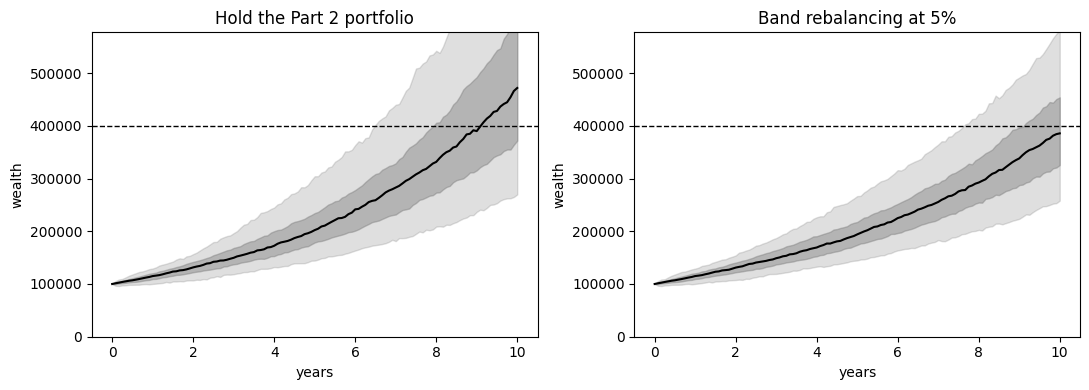

In [14]:
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
months = np.arange(config.HORIZON_MONTHS + 1) / 12.0
for axis, name in ((left, baseline_name), (right, SPECS[2][0])):
    paths = runs[name]["wealth_paths"]
    axis.fill_between(months, np.percentile(paths, 5, axis=0),
                      np.percentile(paths, 95, axis=0), alpha=0.25, color="grey")
    axis.fill_between(months, np.percentile(paths, 25, axis=0),
                      np.percentile(paths, 75, axis=0), alpha=0.45, color="grey")
    axis.plot(months, np.median(paths, axis=0), color="black")
    axis.axhline(reference, linestyle="--", linewidth=1.0, color="black")
    axis.set_xlabel("years")
    axis.set_ylabel("wealth")
    axis.set_title(name)
    axis.set_ylim(0, np.percentile(runs[baseline_name]["wealth_paths"], 97))
plt.tight_layout()
plt.savefig("results/figures/fan.png", dpi=120)
plt.show()

The two fans are drawn on the same vertical scale so the shapes can be compared directly. The band's is visibly narrower at every horizon and its upper edge is far lower, which is the same fact twice: restoring the target repeatedly sells whatever has just risen, and in a decade where the thing that rose kept rising, that is where the 86,000 of median terminal wealth went. The dashed line is the client's target, and the share of each fan finishing below it is the shortfall column of the table above.

In [15]:
start_concentration = float((target ** 2).sum())
rows = []
for name, kind, make, start in SPECS:
    weights_at_end = runs[name]["terminal_weights"]
    concentration = float((weights_at_end ** 2).sum(1).mean())
    rows.append({"policy": name,
                 "effective holdings at the start": 1.0 / float((start ** 2).sum()),
                 "effective holdings at the end": 1.0 / concentration,
                 "largest weight at the end": weights_at_end.max(1).mean(),
                 "largest weight, worst scenario": weights_at_end.max()})
drift = pd.DataFrame(rows)
print(drift.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

                    policy  effective holdings at the start  effective holdings at the end  largest weight at the end  largest weight, worst scenario
 Hold the Part 2 portfolio                            4.449                          2.312                      0.594                           0.877
        Hold equal weights                           25.000                         15.537                      0.141                           0.385
    Band rebalancing at 5%                            4.449                          4.371                      0.315                           0.399
  Re-solve every 12 months                            4.449                          4.498                      0.318                           0.385
      Panic selling at 15%                            4.449                          2.280                      0.578                           1.000
Performance chasing at 0.5                            4.449                          3.120          

This is the table the recommendation turns on. Part 2 caps any single holding at 35%, and it imposes that cap once, at the moment the portfolio is built, while the objective never asks for it again, so nothing in the problem as posed prevents a policy from letting the weights drift straight through it.

They do. Holding ends with a largest position of 59% on average and 88% in the worst of the five hundred scenarios, and equal weights, which never trades either, stays at 14% only because it started with twenty five equal holdings and no single fund can run away from the pack. The two behavioural rules end at 58% and 46%, so neither of them protects the mandate either. Only the band and the re-solving model finish inside the cap, at 32% each.

In [16]:
disciplined = SPECS[2][0]
rows = []
for name in (SPECS[4][0], SPECS[5][0], SPECS[0][0]):
    difference = evaluate.paired_difference(runs[name]["terminal"], runs[disciplined]["terminal"])
    rows.append({"policy": name,
                 "median terminal wealth": np.median(runs[name]["terminal"]),
                 "median difference": difference["median"],
                 "mean difference": difference["mean"],
                 "CI low": difference["ci_low"], "CI high": difference["ci_high"],
                 "share of the disciplined median":
                     np.median(runs[name]["terminal"]) / np.median(runs[disciplined]["terminal"])})
behavioural = pd.DataFrame(rows)
print(f"measured against: {disciplined}")
print(behavioural.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

measured against: Band rebalancing at 5%
                    policy  median terminal wealth  median difference  mean difference     CI low     CI high  share of the disciplined median
      Panic selling at 15%             435,336.699         50,640.929       67,344.257 57,761.445  76,927.068                            1.129
Performance chasing at 0.5             450,397.782         57,011.343       73,515.950 66,968.663  80,063.238                            1.168
 Hold the Part 2 portfolio             471,724.711         78,267.062      106,976.345 97,770.098 116,182.592                            1.223


The brief asks for the cost of the client's tendencies as a change in median terminal wealth against disciplined rebalancing, and measured that way both tendencies come out ahead, at 112.9% and 116.8% of the disciplined median. Reporting that honestly matters more than reporting it comfortably, and the explanation is the one the drift table already gave: panic selling sits out of the market in a third of scenarios and otherwise does nothing, performance chasing tilts toward a winner that kept winning, and both of them spend most of their time letting the portfolio drift, which is what paid in this decade.

The cost of the tendencies is real but it is not visible in the median against a disciplined benchmark. It appears in three other places. Against what the client would otherwise have done, which is to hold, both tendencies lose on the objective, by 13,243 and 8,254 with intervals that exclude zero. It appears in the tail rather than the middle, since panic selling leaves the median untouched while taking 45,000 off the fifth percentile. And it appears once the trigger is set where a nervous client would really set it, which the sensitivity table below shows.

<a id="s5"></a>

## 5. Robustness, and what would change the recommendation

In [17]:
equal_means = data.equalise_means(R)
equal_paths = evaluate.scenarios(equal_means, config.N_EVAL, config.EVAL_SEED)
print(f"cross-sectional spread of annualised means: "
      f"sample {12 * R.mean(0).std():.4f}, equalised {12 * equal_means.mean(0).std():.4f}")

equal_runs = {name: simulator.run_policy(make, equal_paths, start, client, reference)
              for name, kind, make, start in SPECS}
rows = []
for name, kind, make, start in SPECS:
    difference = evaluate.paired_difference(equal_runs[name]["value"],
                                            equal_runs[baseline_name]["value"])
    rows.append({"policy": name, "class": kind,
                 "E[v]": equal_runs[name]["value"].mean(),
                 "median W": np.median(equal_runs[name]["terminal"]),
                 "difference against the baseline": difference["mean"],
                 "CI low": difference["ci_low"], "CI high": difference["ci_high"],
                 "significant": difference["significant"]})
equal_table = pd.DataFrame(rows).sort_values("E[v]", ascending=False)
print()
print(equal_table.to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

cross-sectional spread of annualised means: sample 0.0601, equalised 0.0000


                    policy       class       E[v]   median W  difference against the baseline    CI low   CI high  significant
    Band rebalancing at 5%         PFA -66,494.59 264,727.78                           265.32   -563.94  1,094.57        False
 Hold the Part 2 portfolio    baseline -66,759.91 262,472.21                             0.00      0.00      0.00        False
  Re-solve every 12 months         CFA -67,029.01 264,419.25                          -269.10 -1,171.58    633.38        False
Performance chasing at 0.5 behavioural -67,309.20 260,209.72                          -549.29 -1,768.72    670.14        False
      Panic selling at 15% behavioural -67,730.36 261,541.57                          -970.45 -1,466.92   -473.98         True
        Hold equal weights    baseline -71,400.39 252,577.65                        -4,640.48 -6,210.02 -3,070.94         True


This is the experiment that tells us whether the ranking above is a property of the policies or of the decade. Every fund is given the same expected return, which removes a cross-sectional spread of 6.01% a year, while the covariance matrix and the month-to-month structure are left exactly as they were, so the scenarios differ from the main ones in one respect only: no fund carries a drift advantage over any other.

The 28,370 that doing nothing was worth disappears completely. The band now sits 265 above it with an interval of $[-564, 1{,}095]$, which is to say the two are indistinguishable, and the re-solving model is likewise a tie at $-269$. Nothing here says rebalancing wins; it says the case against it was built entirely out of one decade's cross-section, and that with that cross-section removed discipline is free.

Two differences survive the change. Panic selling still loses, by 970 with an interval of $[-1{,}467, -474]$, so its cost is a property of the rule rather than of the sample, which is what one would expect of a rule that sits out of the market at the worst moments. Equal weights still loses by 4,640, because with every mean equal the twenty five funds are no longer interchangeable on risk and the constrained portfolios are better diversified per unit of volatility.

In [18]:
rows = []
for multiple in config.TARGET_MULTIPLES:
    rho = config.INITIAL_WEALTH * multiple
    for name, kind, make, start in SPECS:
        terminal = runs[name]["terminal"]
        rows.append({"target": f"{multiple:g}x",
                     "policy": name,
                     "E[v]": np.mean(simulator.objective(terminal, rho, client.alpha,
                                                         client.beta, client.lam)),
                     "misses target": (terminal < rho).mean()})
target_table = pd.DataFrame(rows).pivot(index="policy", columns="target", values="E[v]")
shortfall = pd.DataFrame(rows).pivot(index="policy", columns="target", values="misses target")
print("expected value of the objective, by target")
print(target_table.to_string(float_format=lambda v: f"{v:,.0f}"))
print()
print("share of scenarios that miss the target")
print(shortfall.to_string(float_format=lambda v: f"{v:.3f}"))

expected value of the objective, by target
target                         2x     3x      4x
policy                                          
Band rebalancing at 5%     45,157 21,283 -12,598
Hold equal weights         25,456 -7,301 -49,328
Hold the Part 2 portfolio  65,729 43,869  15,771
Panic selling at 15%       57,450 33,216   2,529
Performance chasing at 0.5 59,357 36,903   7,517
Re-solve every 12 months   26,250 -4,655 -49,930

share of scenarios that miss the target
target                        2x    3x    4x
policy                                      
Band rebalancing at 5%     0.006 0.164 0.542
Hold equal weights         0.098 0.504 0.822
Hold the Part 2 portfolio  0.004 0.098 0.320
Panic selling at 15%       0.024 0.186 0.406
Performance chasing at 0.5 0.006 0.102 0.366
Re-solve every 12 months   0.018 0.486 0.914


The target was chosen with the client and the report quotes three of them, because it is an input rather than a measurement and the brief allows either the initial wealth or a target the client names. Holding is the highest-scoring policy at all three, so the ranking is not an artefact of the particular target picked.

What the target does change is whether loss aversion is doing anything at all. A reference at the 100,000 invested would be reached from below in none of the five hundred scenarios, so the loss arm of the value function would never activate and the $\lambda$ of 2.16 that the whole of Part 1 exists to measure would have no effect on any ranking. At twice the initial wealth the shortfall is still small enough that loss aversion barely registers, and only at four times does a third of the scenarios fall short and the parameter start to carry weight. That is why the report leads with the four-times target.

In [19]:
rows = []
for d in config.PANIC_DRAWDOWN_GRID:
    out = simulator.run_policy(policies.panic_selling(target, cash, d, config.PANIC_RECOVERY),
                               eval_paths, target, client, reference)
    rows.append({"drawdown that triggers a sale": d,
                 "fires in": (out["months_traded"] > 0).mean(),
                 "median terminal wealth": np.median(out["terminal"]),
                 "E[v]": out["value"].mean(),
                 "worst fall": out["max_drawdown"].mean()})
panic_table = pd.DataFrame(rows)
print(panic_table.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

 drawdown that triggers a sale  fires in  median terminal wealth        E[v]  worst fall
                         0.100     0.888             331,154.392 -34,459.922       0.127
                         0.150     0.322             435,336.699   2,528.907       0.138
                         0.200     0.078             461,216.285  13,405.174       0.140
                         0.250     0.018             470,903.859  15,340.981       0.141


The trigger is the single most consequential number in the whole report and it is not one we measured, since the questionnaire detects the tendency without pinning the threshold. At 25% the rule fires in 2% of scenarios and costs nothing worth naming; at 15%, the value used above, it fires in a third; at 10% it fires in 89% and takes the median from 471,725 to 331,154.

That last figure deserves to be set against the rebalancing question that occupies the rest of this report. Choosing to rebalance rather than hold costs about 86,000 of median wealth in this sample. A client whose real threshold is 10% rather than 15% loses about 141,000. The behaviour matters more than the policy, which is an uncomfortable conclusion for a report about policies and the right one to give the adviser.

<a id="s6"></a>

## 6. Recommendation to the client

**Rebalance on a 5% band, and treat the trigger that would make you sell as the more urgent problem.**

The honest starting point is that the objective prefers the opposite. Holding the Part 2 portfolio and never trading scores 15,771 against the band's $-12{,}598$ and finishes with a median wealth of 471,725 against 385,631, and the interval around that difference excludes zero, so it is not noise. A recommendation has to answer that, not step around it.

It is answered by what the number leaves out. The portfolio was built under a constraint that no single fund exceed 35%, and that constraint was imposed once, when the portfolio was built, while the objective never asks for it again. Holding ends with 59% in one fund on average and 88% in the worst of five hundred scenarios, so the policy that wins the objective wins it by abandoning the mandate, and an adviser cannot put that in front of the client who was profiled for something else. Once the admissible policies are narrowed to those that keep the cap at the 95th percentile, the widest band that qualifies is 5%, and that is the recommendation.

What it costs is 28,370 of objective and about 86,000 of median terminal wealth, and what it buys is a portfolio that ends with 4.4 effective holdings rather than 2.3, a largest position of 32% rather than 59%, and a worst fall along the way of 11.1% rather than 14.0%. The client should be shown that trade in those terms and allowed to decline it.

Our confidence that the trade is worth taking rests on the robustness test rather than on the main table, because when every fund is given the same expected return the entire advantage of holding vanishes and the two policies become indistinguishable, at 265 with an interval of $[-564, 1{,}095]$. The case for doing nothing was built out of one decade's cross-sectional spread of 6.01% a year, and a client is being asked to bet the next decade on it repeating. Rebalancing is the policy that does not need that bet to pay.

**What would change the recommendation.**

If the client genuinely has no mandate, and is content to end with most of their wealth in whichever fund happened to run, then holding is the better policy on every number in this report and should be recommended instead. The cap is a constraint we were given, not a preference we measured, and a client who waives it is a different client.

If the spread of expected returns across funds is believed to be much smaller than the 6.01% a year this sample showed, which is what the course's own treatment of estimation error would suggest, then the cost of rebalancing is close to zero and the case becomes one-sided.

If the client's true panic threshold is nearer 10% than 15%, the advice changes shape entirely. At that trigger the rule fires in 89% of scenarios and costs about 141,000 of median wealth, which is more than the entire rebalancing decision is worth, so the adviser's effort belongs in pre-committing the client against selling rather than in choosing a band. That is the one recommendation in this report that does not depend on the sample, because panic selling is the only policy that still loses significantly when the drift advantage is removed.

<a id="s7"></a>

## 7. Limitations

**The scenarios inherit the sample they were drawn from.** The block bootstrap resamples the same 129 months used to estimate $\mu$ and $\Sigma$, so the expected returns inside the simulation are the sample's own, and no amount of simulation can reveal the estimation error that section 2.2 is about. Comparisons between policies remain valid, because every policy meets the same scenarios, while the level of terminal wealth is not a forecast: the median implies 16.6% a year, which is a description of 2016 to 2026 and not a projection of the next ten years.

**Dependence longer than six months is destroyed.** Blocks of three to six months preserve whatever serial structure lives inside that window and nothing beyond it, so valuation-driven mean reversion over several years, if it exists, cannot appear in these scenarios. A policy that profits from it would be invisible here.

**One cost model, and nothing else.** Ten basis points on every peso traded, no taxes, no bid-ask spread that widens when it matters, no contributions or withdrawals over ten years, and perfect divisibility. A real client's ten years contain all of these.

**The profile is one administration.** The ten questions were answered once, with no repetition to check stability, and the course's own treatment notes that published loss-aversion estimates range from 1.4 to 3.0 partly because elicitation methods disagree. The ladder brackets the switch point rather than locating it, so this client's 2.16 is a bracket midpoint and a finer ladder would move it.

**The re-solving policy never learns.** It solves with the moments estimated at time zero, which keeps it free of lookahead but also means it cannot react to anything the simulated decade reveals. A version that re-estimated from the path would be a different policy and might rank differently.

**Two thresholds are ours.** The mandate is checked at the 95th percentile across scenarios rather than at the mean or the worst case, and the map from loss aversion to the risk aversion used in Part 2 runs linearly between two anchors we chose. Both are stated where they are used, and both move the answer.

<a id="s8"></a>

## 8. References

- Tversky, A. and Kahneman, D. (1992). Advances in prospect theory: cumulative representation of uncertainty. *Journal of Risk and Uncertainty*, 5(4), 297–323. The value function, the weighting function and the parameter estimates used throughout Part 1.
- Odean, T. (1998). Are investors reluctant to realize their losses? *The Journal of Finance*, 53(5), 1775–1798. The disposition effect, which question 8 of the instrument detects.
- Markowitz, H. (1952). Portfolio selection. *The Journal of Finance*, 7(1), 77–91. The objective of Part 2.
- Michaud, R. (1989). The Markowitz optimization enigma: is optimized optimal? *Financial Analysts Journal*, 45(1), 31–42. Why the optimiser prefers assets carrying positive estimation error.
- Merton, R. (1980). On estimating the expected return on the market. *Journal of Financial Economics*, 8(4), 323–361. Why the mean cannot be estimated precisely from any feasible sample.
- Chopra, V. and Ziemba, W. (1993). The effect of errors in means, variances and covariances on optimal portfolio choice. *Journal of Portfolio Management*, 19(2), 6–11.
- Jagannathan, R. and Ma, T. (2003). Risk reduction in large portfolios: why imposing the wrong constraints helps. *The Journal of Finance*, 58(4), 1651–1683. Why the shrinkage is explicit here.
- DeMiguel, V., Garlappi, L. and Uppal, R. (2009). Optimal versus naive diversification. *Review of Financial Studies*, 22(5), 1915–1953. Why equal weights is carried as a second baseline.
- Powell, W. B. (2022). *Reinforcement Learning and Stochastic Optimization: A Unified Framework for Sequential Decisions*. Wiley. The five elements, the four policy classes and the six-step process.
- Course material: decks 002 mean variance, 003 Prospect Theory, 005 SDA, 007 Policy Classes and 008 PFA and CFA, and the notebooks `Portfolio Optimization.ipynb` and `008 - PFA - CFA 2.ipynb`.